# Laboratorio 06 — Algoritmos fundamentales de teoría de números
**Universidad Nacional de San Antonio Abad del Cusco** · Ingeniería Informática y de Sistemas
**Asignatura:** Algoritmos Avanzados (2026-II) · **Docente:** Héctor Eduardo Ugarte Rojas

**Equipo:** GRUPO 5
**Integrantes:** Choquenaira Quispe, Noe Franklin (133962), Porroa Sivana, Yeni Ruth (120893), Quispe Rimachi, Romario (164257), Yaranga Achahui, Aldo (103179)

---


---

In [16]:
import sys, platform
print("Python", sys.version.split()[0], "|", platform.platform())
assert sys.version_info >= (3, 8), "Se recomienda Python 3.11 o posterior"

Python 3.12.8 | Windows-11-10.0.26300-SP0


## 1. Ejercicios resueltos de la guía
### 1.1 Ejercicio resuelto 1: Euclides con traza y coeficientes de Bézout

In [17]:
def gcd_trace(a, b):
    a, b = abs(a), abs(b)
    trace = []
    while b != 0:
        q, r = divmod(a, b)
        trace.append((a, b, q, r))
        a, b = b, r
    return a, trace


def extended_gcd(a, b):
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y


d, trace = gcd_trace(252, 105)
assert d == 21
assert trace == [(252, 105, 2, 42), (105, 42, 2, 21), (42, 21, 2, 0)]
d, x, y = extended_gcd(252, 105)
assert (d, x, y) == (21, -2, 5)
assert 252 * x + 105 * y == d
print("Traza:")
for fila in trace:
    print("  {} = {}·{} + {}".format(*fila))
print(f"Bézout: {d} = 252·({x}) + 105·({y})")

Traza:
  252 = 105·2 + 42
  105 = 42·2 + 21
  42 = 21·2 + 0
Bézout: 21 = 252·(-2) + 105·(5)


### 1.2 Ejercicio resuelto 2: inversos y congruencias lineales

In [18]:
def modular_inverse(a, n):
    if n <= 1:
        raise ValueError("El modulo debe ser mayor que uno")
    d, x, _ = extended_gcd(a, n)
    if d != 1:
        raise ValueError("El inverso modular no existe")
    return x % n


def solve_linear_congruence(a, b, n):
    if n <= 0:
        raise ValueError("El modulo debe ser positivo")
    d, x, _ = extended_gcd(a, n)
    if b % d != 0:
        return []
    reduced_modulus = n // d
    x0 = (x * (b // d)) % reduced_modulus
    return [(x0 + k * reduced_modulus) % n for k in range(d)]


assert modular_inverse(7, 40) == 23
assert (7 * 23) % 40 == 1
solutions = solve_linear_congruence(14, 30, 100)
assert solutions == [45, 95]
assert all((14 * x - 30) % 100 == 0 for x in solutions)
print("7^(-1) mod 40 =", modular_inverse(7, 40))
print("14x ≡ 30 (mod 100) →", solutions)

7^(-1) mod 40 = 23
14x ≡ 30 (mod 100) → [45, 95]


### 1.3 Ejercicio resuelto 3: exponenciación modular binaria instrumentada

In [19]:
def modular_pow(base, exponent, modulus):
    if modulus <= 0:
        raise ValueError("El modulo debe ser positivo")
    if exponent < 0:
        raise ValueError("El exponente debe ser no negativo")
    result = 1 % modulus
    base %= modulus
    squares = 0
    selected_products = 0
    while exponent > 0:
        if exponent & 1:
            result = (result * base) % modulus
            selected_products += 1
        exponent >>= 1
        if exponent > 0:
            base = (base * base) % modulus
            squares += 1
    return result, squares, selected_products


value, squares, products = modular_pow(7, 13, 20)
assert value == pow(7, 13, 20) == 7
assert squares == 3 and products == 3
print(f"7^13 mod 20 = {value} | cuadrados = {squares} | productos = {products} | 13 = {bin(13)}")

7^13 mod 20 = 7 | cuadrados = 3 | productos = 3 | 13 = 0b1101


## 2. Biblioteca integrada `number_theory.py` (Ejercicio propuesto 1)
Reúne la interfaz requerida, el TCR con traza y un verificador. Cada función documenta **precondiciones, poscondiciones y excepciones**.

In [20]:
%%writefile number_theory.py
"""
number_theory.py
================

Biblioteca de algoritmos fundamentales de teoría de números.
Guía de Laboratorio N.º 06 - Algoritmos Avanzados (UNSAAC, 2026-II).

Funciones de la interfaz requerida
----------------------------------
- gcd_trace(a, b)                      -> (d, traza)
- extended_gcd(a, b)                   -> (d, x, y)
- modular_inverse(a, n)                -> u
- solve_linear_congruence(a, b, n)     -> [x_0, ..., x_{d-1}]
- modular_pow(base, exponent, modulus) -> (valor, cuadrados, productos)
- crt(residues, moduli)                -> (x, N)
- validate_crt_solution(x, residues, moduli) -> bool

Funciones auxiliares
--------------------
- crt_with_trace(residues, moduli)     -> (x, N, traza)
- naive_pow_multiplications(exponent)  -> número de multiplicaciones del método directo

Convención para (0, 0): mcd(0, 0) = 0 (convención usada por math.gcd).
La traza para (0, 0) es vacía y extended_gcd(0, 0) devuelve (0, 0, 0),
que satisface trivialmente 0*0 + 0*0 = 0.
"""

from math import prod

__all__ = [
    "gcd_trace",
    "extended_gcd",
    "modular_inverse",
    "solve_linear_congruence",
    "modular_pow",
    "crt",
    "crt_with_trace",
    "validate_crt_solution",
    "naive_pow_multiplications",
]


def _check_int(*values):
    """Verifica que todos los argumentos sean enteros (no bool)."""
    for v in values:
        if not isinstance(v, int) or isinstance(v, bool):
            raise TypeError(f"Se esperaba un entero y se recibió {type(v).__name__}")


# ---------------------------------------------------------------------------
# 1. Algoritmo de Euclides con traza
# ---------------------------------------------------------------------------
def gcd_trace(a, b):
    """Calcula mcd(a, b) con el algoritmo de Euclides y registra cada división.

    Precondiciones:
        a, b son enteros (pueden ser negativos o cero).
    Poscondiciones:
        Devuelve (d, trace) donde d = mcd(|a|, |b|) >= 0 y trace es una lista
        de tuplas (a_i, b_i, q_i, r_i) que cumplen a_i = b_i*q_i + r_i y
        0 <= r_i < b_i. len(trace) es el número de divisiones realizadas.
        Para (0, 0) se devuelve (0, []) por convención.
    Excepciones:
        TypeError si algún argumento no es entero.
    """
    _check_int(a, b)
    a, b = abs(a), abs(b)
    trace = []
    while b != 0:
        q, r = divmod(a, b)
        trace.append((a, b, q, r))
        a, b = b, r
    return a, trace


# ---------------------------------------------------------------------------
# 2. Euclides extendido (forma iterativa)
# ---------------------------------------------------------------------------
def extended_gcd(a, b):
    """Calcula d = mcd(a, b) y coeficientes de Bézout x, y con a*x + b*y = d.

    Precondiciones:
        a, b son enteros.
    Poscondiciones:
        Devuelve (d, x, y) con d >= 0 y a*x + b*y == d.
        Para (0, 0) devuelve (0, 0, 0).
    Excepciones:
        TypeError si algún argumento no es entero.
    """
    _check_int(a, b)
    old_r, r = abs(a), abs(b)
    old_s, s = 1, 0
    old_t, t = 0, 1
    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t
    if old_r == 0:          # caso (0, 0)
        return 0, 0, 0
    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y


# ---------------------------------------------------------------------------
# 3. Inverso modular
# ---------------------------------------------------------------------------
def modular_inverse(a, n):
    """Calcula el inverso de a módulo n.

    Precondiciones:
        a entero cualquiera (puede ser negativo o mayor que n); n entero > 1.
    Poscondiciones:
        Devuelve u en {1, ..., n-1} tal que (a*u) % n == 1.
    Excepciones:
        ValueError si n <= 1 o si mcd(a, n) != 1 (el inverso no existe).
        TypeError si algún argumento no es entero.
    """
    _check_int(a, n)
    if n <= 1:
        raise ValueError("El modulo debe ser mayor que uno")
    d, x, _ = extended_gcd(a, n)
    if d != 1:
        raise ValueError(f"El inverso modular no existe: mcd({a}, {n}) = {d}")
    return x % n


# ---------------------------------------------------------------------------
# 4. Congruencias lineales a x ≡ b (mod n)
# ---------------------------------------------------------------------------
def solve_linear_congruence(a, b, n):
    """Resuelve a*x ≡ b (mod n) y devuelve todas las soluciones módulo n.

    Precondiciones:
        a, b enteros; n entero > 0.
    Poscondiciones:
        Si d = mcd(a, n) no divide a b, devuelve [].
        En otro caso devuelve una lista ordenada de exactamente d valores
        distintos en {0, ..., n-1}, cada uno con (a*x - b) % n == 0.
        Caso especial: si a ≡ 0 (mod n), d = n y la congruencia 0 ≡ b
        tiene n soluciones si b ≡ 0 y ninguna en otro caso.
    Excepciones:
        ValueError si n <= 0. TypeError si algún argumento no es entero.
    """
    _check_int(a, b, n)
    if n <= 0:
        raise ValueError("El modulo debe ser positivo")
    a %= n
    b %= n
    if a == 0:
        return list(range(n)) if b == 0 else []
    d, x, _ = extended_gcd(a, n)
    if b % d != 0:
        return []
    reduced_modulus = n // d
    x0 = (x * (b // d)) % reduced_modulus
    return sorted((x0 + k * reduced_modulus) % n for k in range(d))


# ---------------------------------------------------------------------------
# 5. Exponenciación modular binaria instrumentada
# ---------------------------------------------------------------------------
def modular_pow(base, exponent, modulus):
    """Calcula base**exponent mod modulus por cuadrados sucesivos (derecha a izquierda).

    Precondiciones:
        base entero cualquiera; exponent entero >= 0; modulus entero > 0.
    Poscondiciones:
        Devuelve (valor, squares, selected_products) donde
          valor == pow(base, exponent, modulus),
          squares == max(exponent.bit_length() - 1, 0),
          selected_products == número de bits 1 de exponent (popcount).
        Nunca se construye la potencia completa: todo intermedio es < modulus**2.
    Excepciones:
        ValueError si modulus <= 0 o exponent < 0. TypeError si no son enteros.
    """
    _check_int(base, exponent, modulus)
    if modulus <= 0:
        raise ValueError("El modulo debe ser positivo")
    if exponent < 0:
        raise ValueError("El exponente debe ser no negativo")
    result = 1 % modulus
    base %= modulus
    squares = 0
    selected_products = 0
    while exponent > 0:
        if exponent & 1:
            result = (result * base) % modulus
            selected_products += 1
        exponent >>= 1
        if exponent > 0:
            base = (base * base) % modulus
            squares += 1
    return result, squares, selected_products


def naive_pow_multiplications(exponent):
    """Número de multiplicaciones del método directo a*a*...*a: e - 1 (0 si e <= 1)."""
    return max(exponent - 1, 0)


# ---------------------------------------------------------------------------
# 6. Teorema chino del resto
# ---------------------------------------------------------------------------
def _validate_crt_input(residues, moduli):
    """Valida longitudes, módulos > 1 y coprimalidad dos a dos."""
    residues = list(residues)
    moduli = list(moduli)
    if len(residues) == 0 or len(moduli) == 0:
        raise ValueError("Las listas de residuos y modulos no pueden estar vacias")
    if len(residues) != len(moduli):
        raise ValueError("Residuos y modulos deben tener la misma longitud")
    _check_int(*residues, *moduli)
    for n in moduli:
        if n <= 1:
            raise ValueError(f"Todos los modulos deben ser mayores que uno (se recibio {n})")
    k = len(moduli)
    for i in range(k):
        for j in range(i + 1, k):
            g, _ = gcd_trace(moduli[i], moduli[j])
            if g != 1:
                raise ValueError(
                    f"Los modulos {moduli[i]} y {moduli[j]} no son coprimos (mcd = {g})"
                )
    return residues, moduli


def crt_with_trace(residues, moduli):
    """TCR con traza de construcción.

    Precondiciones:
        residues y moduli son listas no vacías de igual longitud, de enteros;
        cada n_i > 1 y mcd(n_i, n_j) = 1 para i != j. Los residuos pueden ser
        negativos o mayores que su módulo.
    Poscondiciones:
        Devuelve (x, N, trace) con N = prod(n_i), 0 <= x < N, x ≡ a_i (mod n_i)
        para todo i, y trace una lista de diccionarios con claves
        i, a_i, n_i, N_i, M_i, a_i*N_i*M_i (a_i normalizado en [0, n_i)).
        No realiza búsqueda exhaustiva: costo O(k^2 log N) operaciones aritméticas.
    Excepciones:
        ValueError ante listas vacías, longitudes distintas, módulos <= 1
        o módulos no coprimos. TypeError si hay valores no enteros.
    """
    residues, moduli = _validate_crt_input(residues, moduli)
    N = prod(moduli)
    total = 0
    trace = []
    for i, (a_i, n_i) in enumerate(zip(residues, moduli), start=1):
        a_norm = a_i % n_i
        N_i = N // n_i
        M_i = modular_inverse(N_i % n_i, n_i)
        term = a_norm * N_i * M_i
        total += term
        trace.append({"i": i, "a_i": a_norm, "n_i": n_i, "N_i": N_i,
                      "M_i": M_i, "a_i*N_i*M_i": term})
    return total % N, N, trace


def crt(residues, moduli):
    """Resuelve x ≡ a_i (mod n_i) para módulos coprimos dos a dos.

    Devuelve (x, N): x es el menor representante no negativo y N = prod(n_i).
    Ver crt_with_trace para precondiciones y excepciones.
    """
    x, N, _ = crt_with_trace(residues, moduli)
    return x, N


def validate_crt_solution(x, residues, moduli):
    """Comprueba que x satisface simultáneamente todas las congruencias x ≡ a_i (mod n_i).

    Precondiciones: listas de igual longitud y módulos positivos.
    Poscondiciones: True si (x - a_i) % n_i == 0 para todo i; False en otro caso.
    Excepciones: ValueError si las longitudes difieren o algún módulo es <= 0.
    """
    residues = list(residues)
    moduli = list(moduli)
    if len(residues) != len(moduli):
        raise ValueError("Residuos y modulos deben tener la misma longitud")
    if any(n <= 0 for n in moduli):
        raise ValueError("Los modulos deben ser positivos")
    return all((x - a) % n == 0 for a, n in zip(residues, moduli))


if __name__ == "__main__":
    # Ejecución rápida de los casos de la guía
    print(gcd_trace(252, 105))
    print(extended_gcd(252, 105))
    print(modular_inverse(7, 40))
    print(solve_linear_congruence(14, 30, 100))
    print(modular_pow(7, 13, 20))
    x, N, tr = crt_with_trace([2, 3, 2], [3, 5, 7])
    print((x, N))
    for row in tr:
        print(row)

Overwriting number_theory.py


## 3. Generador reproducible de casos aleatorios `case_generator.py`

In [21]:
%%writefile case_generator.py
"""
case_generator.py
=================

Generador reproducible de casos aleatorios para la Guía 06.
Todas las funciones reciben un objeto random.Random inicializado con una
semilla fija, de modo que cada experimento puede repetirse exactamente.
"""

import random
from math import gcd

SEED = 20262  # semilla global del laboratorio (2026-II)

FIB_PAIRS = [(13, 8), (89, 55), (6765, 4181), (832040, 514229)]


def make_rng(seed=SEED):
    """Crea un generador pseudoaleatorio reproducible."""
    return random.Random(seed)


def random_int_bits(rng, bits):
    """Entero aleatorio con exactamente `bits` bits (el bit más alto es 1)."""
    if bits <= 0:
        return 0
    return rng.getrandbits(bits) | (1 << (bits - 1))


def random_pair(rng, bits, allow_negative=True):
    """Par (a, b) con `bits` bits cada uno y signo aleatorio opcional."""
    a = random_int_bits(rng, bits)
    b = random_int_bits(rng, bits)
    if allow_negative:
        if rng.random() < 0.25:
            a = -a
        if rng.random() < 0.25:
            b = -b
    return a, b


def exponent_with_popcount(rng, bits, ones):
    """Exponente de `bits` bits con exactamente `ones` bits iguales a 1 (el más alto incluido)."""
    if not 1 <= ones <= bits:
        raise ValueError("ones debe estar entre 1 y bits")
    positions = rng.sample(range(bits - 1), ones - 1)
    e = 1 << (bits - 1)
    for p in positions:
        e |= 1 << p
    return e


def random_coprime_moduli(rng, k, low=2, high=10_000):
    """Lista de k módulos > 1 coprimos dos a dos."""
    moduli = []
    while len(moduli) < k:
        candidate = rng.randint(low, high)
        if all(gcd(candidate, m) == 1 for m in moduli):
            moduli.append(candidate)
    return moduli


def random_crt_system(rng, k, low=2, high=10_000):
    """Sistema TCR construido a partir de una solución conocida.

    Devuelve (x_conocida, residuos, módulos). Los residuos se desplazan con
    múltiplos aleatorios del módulo para obtener valores no normalizados.
    """
    moduli = random_coprime_moduli(rng, k, low, high)
    N = 1
    for m in moduli:
        N *= m
    x_known = rng.randrange(N)
    residues = [x_known % m + rng.randint(-3, 3) * m for m in moduli]
    return x_known, residues, moduli


def random_congruence(rng, n_max=1000, force_solvable=None):
    """Congruencia a x ≡ b (mod n). force_solvable=True/False fuerza el tipo."""
    while True:
        n = rng.randint(2, n_max)
        a = rng.randint(-n_max, n_max)
        b = rng.randint(-n_max, n_max)
        if a % n == 0:
            continue
        d = gcd(a, n)
        solvable = (b % d == 0)
        if force_solvable is None or force_solvable == solvable:
            return a, b, n

Overwriting case_generator.py


## 4. Pruebas automatizadas de propiedades y casos excepcionales

> **Nota:** si esta celda se ejecuta nuevamente, Colab puede mostrar `Overwriting test_number_theory.py`. Esto solo significa que está regenerando el archivo auxiliar; no es un error ni el resultado de una prueba. Los resultados de cada caso aparecen en la celda siguiente como `ok`, junto con el resumen `Ran 34 tests ... OK`.

In [22]:
%%writefile test_number_theory.py
"""
test_number_theory.py
=====================

Pruebas automatizadas de propiedades y casos excepcionales (Guía 06).
Se usa unittest para que funcione en Google Colab sin instalar nada:
    import unittest, test_number_theory
    unittest.main(module=test_number_theory, argv=[""], exit=False, verbosity=2)
"""

import math
import unittest
from itertools import permutations

from number_theory import (crt, crt_with_trace, extended_gcd, gcd_trace,
                           modular_inverse, modular_pow,
                           solve_linear_congruence, validate_crt_solution)
from case_generator import (FIB_PAIRS, exponent_with_popcount, make_rng,
                            random_congruence, random_crt_system, random_pair)


def check_trace(a, b, d, trace):
    """Propiedad 1: cada fila cumple a_i = b_i q_i + r_i y 0 <= r_i < |b_i|."""
    for (ai, bi, qi, ri) in trace:
        assert ai == bi * qi + ri, (ai, bi, qi, ri)
        assert 0 <= ri < abs(bi), (ai, bi, qi, ri)
    if trace:
        assert trace[-1][3] == 0
        assert trace[-1][1] == d


class TestEuclides(unittest.TestCase):
    def test_caso_guia(self):
        d, trace = gcd_trace(252, 105)
        self.assertEqual(d, 21)
        self.assertEqual(trace, [(252, 105, 2, 42), (105, 42, 2, 21), (42, 21, 2, 0)])
        self.assertEqual(extended_gcd(252, 105), (21, -2, 5))

    def test_ceros(self):
        self.assertEqual(gcd_trace(17, 0), (17, []))
        self.assertEqual(gcd_trace(0, 17)[0], 17)
        self.assertEqual(gcd_trace(0, 0), (0, []))         # convención documentada
        self.assertEqual(extended_gcd(0, 0), (0, 0, 0))
        for a, b in [(17, 0), (0, 17), (-9, 0), (0, -9)]:
            d, x, y = extended_gcd(a, b)
            self.assertEqual(a * x + b * y, d)

    def test_signos_e_intercambio(self):
        for a, b in [(252, 105), (-252, 105), (252, -105), (-252, -105),
                     (105, 252), (-105, -252)]:
            d, trace = gcd_trace(a, b)
            self.assertEqual(d, math.gcd(a, b))
            check_trace(a, b, d, trace)
            d2, x, y = extended_gcd(a, b)
            self.assertEqual(d2, d)
            self.assertEqual(a * x + b * y, d)

    def test_coprimos_y_no_coprimos(self):
        self.assertEqual(gcd_trace(35, 64)[0], 1)
        self.assertEqual(gcd_trace(48, 180)[0], 12)

    def test_fibonacci_peor_caso(self):
        # Pares consecutivos de Fibonacci: máximo número de divisiones (Lamé)
        for a, b in FIB_PAIRS:
            d, trace = gcd_trace(a, b)
            self.assertEqual(d, 1)
            check_trace(a, b, d, trace)
        self.assertEqual(len(gcd_trace(89, 55)[1]), 9)

    def test_aleatorio_contra_math_gcd(self):
        rng = make_rng(1)
        for bits in (8, 16, 32, 64, 128, 256, 512):
            for _ in range(100):
                a, b = random_pair(rng, bits)
                d, trace = gcd_trace(a, b)
                self.assertEqual(d, math.gcd(a, b))
                check_trace(a, b, d, trace)
                d2, x, y = extended_gcd(a, b)
                self.assertEqual(a * x + b * y, d2)

    def test_tipo_invalido(self):
        with self.assertRaises(TypeError):
            gcd_trace(2.5, 3)


class TestInversoYCongruencias(unittest.TestCase):
    def test_inverso_existente(self):
        self.assertEqual(modular_inverse(7, 40), 23)
        self.assertEqual((7 * 23) % 40, 1)

    def test_inverso_residuo_negativo_y_grande(self):
        u = modular_inverse(-3, 11)
        self.assertEqual((-3 * u) % 11, 1)
        self.assertEqual(u, 7)
        self.assertEqual(modular_inverse(47, 40), modular_inverse(7, 40))

    def test_inverso_inexistente(self):
        for a, n in [(6, 9), (10, 25), (0, 7), (14, 100)]:
            with self.assertRaises(ValueError):
                modular_inverse(a, n)

    def test_modulo_invalido(self):
        for n in (1, 0, -5):
            with self.assertRaises(ValueError):
                modular_inverse(3, n)

    def test_inverso_existe_sii_mcd_1(self):
        for n in range(2, 60):
            for a in range(-n, 2 * n):
                if math.gcd(a, n) == 1:
                    u = modular_inverse(a, n)
                    self.assertEqual((a * u) % n, 1)
                    self.assertTrue(0 < u < n)
                    self.assertEqual(u, pow(a, -1, n))
                else:
                    with self.assertRaises(ValueError):
                        modular_inverse(a, n)

    def test_congruencia_guia(self):
        sol = solve_linear_congruence(14, 30, 100)
        self.assertEqual(sol, [45, 95])
        self.assertTrue(all((14 * x - 30) % 100 == 0 for x in sol))

    def test_congruencia_sin_solucion(self):
        self.assertEqual(solve_linear_congruence(6, 4, 9), [])

    def test_congruencia_una_solucion(self):
        self.assertEqual(solve_linear_congruence(7, 3, 40), [(23 * 3) % 40])

    def test_congruencia_varias_soluciones(self):
        sol = solve_linear_congruence(12, 18, 30)
        self.assertEqual(len(sol), 6)
        self.assertTrue(all((12 * x - 18) % 30 == 0 for x in sol))

    def test_congruencia_a_cero(self):
        self.assertEqual(solve_linear_congruence(0, 0, 4), [0, 1, 2, 3])
        self.assertEqual(solve_linear_congruence(10, 3, 5), [])

    def test_congruencia_modulo_invalido(self):
        with self.assertRaises(ValueError):
            solve_linear_congruence(3, 1, 0)

    def test_congruencias_exhaustivo(self):
        for n in range(1, 40):
            for a in range(-5, n + 5):
                for b in range(-3, n + 3):
                    brute = [x for x in range(n) if (a * x - b) % n == 0]
                    self.assertEqual(solve_linear_congruence(a, b, n), brute)

    def test_congruencias_aleatorias(self):
        rng = make_rng(2)
        for _ in range(500):
            a, b, n = random_congruence(rng)
            d = math.gcd(a, n)
            sol = solve_linear_congruence(a, b, n)
            if b % d == 0:
                self.assertEqual(len(sol), d)
                self.assertEqual(len(set(sol)), d)
                self.assertTrue(all(0 <= x < n and (a * x - b) % n == 0 for x in sol))
            else:
                self.assertEqual(sol, [])


class TestPotenciaModular(unittest.TestCase):
    def test_caso_guia(self):
        self.assertEqual(modular_pow(7, 13, 20), (7, 3, 3))

    def test_bordes(self):
        self.assertEqual(modular_pow(5, 0, 7)[0], 1)     # exponente cero
        self.assertEqual(modular_pow(0, 5, 7)[0], 0)     # base cero
        self.assertEqual(modular_pow(0, 0, 7)[0], 1)     # convención 0^0 = 1, igual que pow
        self.assertEqual(modular_pow(5, 3, 1)[0], 0)     # módulo uno
        self.assertEqual(modular_pow(5, 0, 1)[0], 0)
        self.assertEqual(modular_pow(-2, 3, 7)[0], pow(-2, 3, 7))

    def test_errores(self):
        with self.assertRaises(ValueError):
            modular_pow(2, -1, 7)
        with self.assertRaises(ValueError):
            modular_pow(2, 3, 0)

    def test_conteo_operaciones(self):
        rng = make_rng(3)
        for bits in (8, 64, 1024):
            for ones in (1, bits // 2, bits):
                e = exponent_with_popcount(rng, bits, ones)
                _, sq, pr = modular_pow(3, e, 1_000_000_007)
                self.assertEqual(sq, bits - 1)
                self.assertEqual(pr, ones)
                self.assertEqual(pr, bin(e).count("1"))

    def test_muchos_bits_contra_pow(self):
        rng = make_rng(4)
        for bits in (8, 16, 32, 64, 128, 256, 512, 1024, 2048):
            for _ in range(20):
                base = rng.getrandbits(bits)
                e = rng.getrandbits(bits)
                m = rng.getrandbits(bits) | 1
                self.assertEqual(modular_pow(base, e, m)[0], pow(base, e, m))


class TestTCR(unittest.TestCase):
    def test_caso_obligatorio(self):
        x, N, trace = crt_with_trace([2, 3, 2], [3, 5, 7])
        self.assertEqual((x, N), (23, 105))
        self.assertEqual([(r["N_i"], r["M_i"]) for r in trace], [(35, 2), (21, 1), (15, 1)])
        self.assertTrue(validate_crt_solution(x, [2, 3, 2], [3, 5, 7]))

    def test_una_congruencia(self):
        self.assertEqual(crt([4], [9]), (4, 9))
        self.assertEqual(crt([-1], [9]), (8, 9))

    def test_residuos_no_normalizados(self):
        self.assertEqual(crt([-1, 13, 9], [3, 5, 7]), (23, 105))

    def test_orden_de_modulos(self):
        res, mod = [2, 3, 2], [3, 5, 7]
        for perm in permutations(range(3)):
            r = [res[i] for i in perm]
            m = [mod[i] for i in perm]
            self.assertEqual(crt(r, m), (23, 105))

    def test_listas_invalidas(self):
        with self.assertRaises(ValueError):
            crt([], [])
        with self.assertRaises(ValueError):
            crt([1, 2], [3])
        with self.assertRaises(ValueError):
            crt([1], [1])
        with self.assertRaises(ValueError):
            crt([1, 2], [0, 5])

    def test_modulos_no_coprimos(self):
        with self.assertRaises(ValueError):
            crt([1, 2], [6, 6])     # repetidos
        with self.assertRaises(ValueError):
            crt([1, 2], [4, 6])     # mcd = 2

    def test_contra_busqueda_exhaustiva(self):
        rng = make_rng(5)
        for _ in range(200):
            _, r, m = random_crt_system(rng, rng.randint(1, 3), 2, 30)
            x, N = crt(r, m)
            brute = next(t for t in range(N) if validate_crt_solution(t, r, m))
            self.assertEqual(x, brute)

    def test_sistemas_con_solucion_conocida(self):
        rng = make_rng(6)
        for _ in range(500):
            x_known, r, m = random_crt_system(rng, rng.randint(1, 6))
            x, N = crt(r, m)
            self.assertEqual(x, x_known % N)
            self.assertTrue(0 <= x < N)
            self.assertTrue(validate_crt_solution(x, r, m))

    def test_validador(self):
        self.assertTrue(validate_crt_solution(128, [2, 3, 2], [3, 5, 7]))
        self.assertFalse(validate_crt_solution(24, [2, 3, 2], [3, 5, 7]))


if __name__ == "__main__":
    unittest.main(verbosity=2)

Overwriting test_number_theory.py


In [23]:
import importlib, unittest
import number_theory, case_generator, test_number_theory
for m in (number_theory, case_generator, test_number_theory):
    importlib.reload(m)
resultado = unittest.main(module=test_number_theory, argv=[""], exit=False, verbosity=2).result
print(f"\nPruebas ejecutadas: {resultado.testsRun} | fallos: {len(resultado.failures)} | errores: {len(resultado.errors)}")

test_aleatorio_contra_math_gcd (test_number_theory.TestEuclides.test_aleatorio_contra_math_gcd) ... ok
test_caso_guia (test_number_theory.TestEuclides.test_caso_guia) ... ok
test_ceros (test_number_theory.TestEuclides.test_ceros) ... ok
test_coprimos_y_no_coprimos (test_number_theory.TestEuclides.test_coprimos_y_no_coprimos) ... ok
test_fibonacci_peor_caso (test_number_theory.TestEuclides.test_fibonacci_peor_caso) ... ok
test_signos_e_intercambio (test_number_theory.TestEuclides.test_signos_e_intercambio) ... ok
test_tipo_invalido (test_number_theory.TestEuclides.test_tipo_invalido) ... ok
test_congruencia_a_cero (test_number_theory.TestInversoYCongruencias.test_congruencia_a_cero) ... ok
test_congruencia_guia (test_number_theory.TestInversoYCongruencias.test_congruencia_guia) ... ok
test_congruencia_modulo_invalido (test_number_theory.TestInversoYCongruencias.test_congruencia_modulo_invalido) ... ok
test_congruencia_sin_solucion (test_number_theory.TestInversoYCongruencias.test_congru


Pruebas ejecutadas: 34 | fallos: 0 | errores: 0


## 5. Teorema chino del resto: caso obligatorio con traza
$x \equiv 2 \pmod 3,\; x \equiv 3 \pmod 5,\; x \equiv 2 \pmod 7$

In [24]:
import pandas as pd
from number_theory import crt_with_trace, validate_crt_solution, crt

residuos, modulos = [2, 3, 2], [3, 5, 7]
x, N, traza = crt_with_trace(residuos, modulos)
print("(x, N) =", (x, N))
assert (x, N) == (23, 105)
assert [(f["N_i"], f["M_i"]) for f in traza] == [(35, 2), (21, 1), (15, 1)]
assert validate_crt_solution(x, residuos, modulos)
display(pd.DataFrame(traza))
print("Suma de términos =", sum(f["a_i*N_i*M_i"] for f in traza), "→", sum(f["a_i*N_i*M_i"] for f in traza), "mod", N, "=", x)

# Casos excepcionales documentados
for r, m in [([], []), ([1, 2], [3]), ([1, 2], [6, 6]), ([1, 2], [4, 6]), ([1], [1])]:
    try:
        crt(r, m)
    except ValueError as e:
        print(f"crt({r}, {m}) → ValueError: {e}")

(x, N) = (23, 105)


,i,a_i,n_i,N_i,M_i,a_i*N_i*M_i
0,1,2,3,35,2,140
1,2,3,5,21,1,63
2,3,2,7,15,1,30


Suma de términos = 233 → 233 mod 105 = 23
crt([], []) → ValueError: Las listas de residuos y modulos no pueden estar vacias
crt([1, 2], [3]) → ValueError: Residuos y modulos deben tener la misma longitud
crt([1, 2], [6, 6]) → ValueError: Los modulos 6 y 6 no son coprimos (mcd = 6)
crt([1, 2], [4, 6]) → ValueError: Los modulos 4 y 6 no son coprimos (mcd = 2)
crt([1], [1]) → ValueError: Todos los modulos deben ser mayores que uno (se recibio 1)


## 6. Experimentos reproducibles (Ejercicio propuesto 2)
- **Escenario A:** 7000 pares aleatorios (1000 por cada tamaño de 8 a 512 bits) contra `math.gcd` y verificación de Bézout.
- **Escenario B:** exponentes de 8 a 1024 bits contra `pow`; cuadrados, productos, tiempo y comparación con $e-1$.
- **Escenario C:** inversos, congruencias y sistemas TCR con solución conocida.

Las entradas se generan **antes** de medir, con semillas fijas; no se imprime ni escribe dentro del intervalo medido.

In [25]:
%%writefile experiments.py
"""
experiments.py
==============

Escenarios experimentales A, B y C de la Guía 06 (Ejercicio propuesto 2) y
generación de tablas (CSV) y gráficos (PNG). Totalmente reproducible: cada
escenario usa su propia semilla fija, registrada en los CSV.

Uso:  python experiments.py     (o ejecutar las celdas del notebook en Colab)
"""

import csv
import math
import os
from statistics import mean, median
from time import perf_counter_ns

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from number_theory import (crt_with_trace, extended_gcd, gcd_trace,
                           modular_inverse, modular_pow,
                           naive_pow_multiplications, solve_linear_congruence,
                           validate_crt_solution, crt)
from case_generator import (FIB_PAIRS, exponent_with_popcount, make_rng,
                            random_congruence, random_crt_system,
                            random_int_bits, random_pair)

RESULTS = "results"
FIGURES = "figures"
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(FIGURES, exist_ok=True)

SEED_A, SEED_B, SEED_C = 6001, 6002, 6003
BITS_A = [8, 16, 32, 64, 128, 256, 512]
PAIRS_PER_BITS = 1000                      # 7 x 1000 = 7000 pares (>= 5000)
BITS_B = [8, 16, 32, 64, 128, 256, 512, 1024]
EXPONENTS_PER_BITS = 30
PHI = (1 + 5 ** 0.5) / 2

# Paleta (referencia validada, slots 1-3) y estilo sobrio para impresión
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Serif", "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
    "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
    "figure.dpi": 150, "savefig.bbox": "tight",
})


def measure(function, repetitions=10):
    """Medición de la guía: devuelve mínimo, mediana y máximo en nanosegundos."""
    times = []
    for _ in range(repetitions):
        start = perf_counter_ns()
        function()
        end = perf_counter_ns()
        times.append(end - start)
    return {"min_ns": min(times), "median_ns": median(times), "max_ns": max(times)}


def write_csv(path, rows):
    with open(path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


# ---------------------------------------------------------------------------
# Escenario A: pruebas diferenciales de Euclides
# ---------------------------------------------------------------------------
def scenario_a():
    rng = make_rng(SEED_A)
    pairs = [(bits, *random_pair(rng, bits)) for bits in BITS_A
             for _ in range(PAIRS_PER_BITS)]          # entradas generadas antes de medir
    rows, discrepancies = [], []
    for idx, (bits, a, b) in enumerate(pairs):
        d, trace = gcd_trace(a, b)
        d2, x, y = extended_gcd(a, b)
        ok_gcd = d == math.gcd(a, b)
        ok_bezout = (a * x + b * y == d2) and d2 == d
        if not (ok_gcd and ok_bezout):
            discrepancies.append({"seed": SEED_A, "index": idx, "a": a, "b": b})
        rows.append({"seed": SEED_A, "index": idx, "bits": bits, "a": a, "b": b,
                     "gcd": d, "divisions": len(trace),
                     "bit_length_min": min(abs(a), abs(b)).bit_length(),
                     "gcd_ok": ok_gcd, "bezout_ok": ok_bezout})
    write_csv(f"{RESULTS}/escenario_A_euclides.csv", rows)
    if discrepancies:
        write_csv(f"{RESULTS}/escenario_A_discrepancias.csv", discrepancies)

    summary = []
    for bits in BITS_A:
        sub = [r for r in rows if r["bits"] == bits]
        divs = [r["divisions"] for r in sub]
        summary.append({
            "bits": bits, "pares": len(sub),
            "div_media": round(mean(divs), 2), "div_mediana": median(divs),
            "div_max": max(divs),
            "teorico_medio": round(12 * math.log(2) ** 2 / math.pi ** 2 * bits, 2),
            "cota_lame": math.ceil(bits * math.log(2) / math.log(PHI)) + 1,
            "mcd_1_pct": round(100 * sum(r["gcd"] == 1 for r in sub) / len(sub), 1),
            "gcd_ok": all(r["gcd_ok"] for r in sub),
            "bezout_ok": all(r["bezout_ok"] for r in sub),
        })
    write_csv(f"{RESULTS}/escenario_A_resumen.csv", summary)

    # Tabla de MCD de casos representativos y Fibonacci
    examples = [(252, 105), (-252, 105), (48, 180), (35, 64), (17, 0), (0, 17)] + FIB_PAIRS
    ex_rows = []
    for a, b in examples:
        d, trace = gcd_trace(a, b)
        _, x, y = extended_gcd(a, b)
        ex_rows.append({"a": a, "b": b, "mcd": d, "divisiones": len(trace),
                        "bits": max(abs(a), abs(b)).bit_length(), "x": x, "y": y,
                        "bezout": a * x + b * y == d})
    write_csv(f"{RESULTS}/tabla_mcd_ejemplos.csv", ex_rows)

    # Tiempos de Euclides por tamaño (sobre 50 pares fijos por tamaño)
    time_rows = []
    for bits in BITS_A:
        sub = [(a, b) for (bb, a, b) in pairs if bb == bits][:50]
        t = measure(lambda: [gcd_trace(a, b) for a, b in sub], repetitions=7)
        time_rows.append({"bits": bits, "pares": len(sub),
                          "median_us_por_par": round(t["median_ns"] / len(sub) / 1000, 3),
                          "min_us_por_par": round(t["min_ns"] / len(sub) / 1000, 3),
                          "max_us_por_par": round(t["max_ns"] / len(sub) / 1000, 3)})
    write_csv(f"{RESULTS}/escenario_A_tiempos.csv", time_rows)

    # Figura 1: divisiones vs bits
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.plot(BITS_A, [s["cota_lame"] for s in summary], color=C2, marker="s",
            linestyle="--", label="Cota de Lamé (peor caso)")
    ax.plot(BITS_A, [s["div_max"] for s in summary], color=C3, marker="^",
            label="Máximo observado")
    ax.plot(BITS_A, [s["div_media"] for s in summary], color=C1, marker="o",
            label="Media observada")
    ax.plot(BITS_A, [s["teorico_medio"] for s in summary], color=INK2,
            linestyle=":", linewidth=1.5, label="Media teórica ≈ 0.584·bits")
    ax.set_xticks([8, 64, 128, 256, 512])
    ax.set_xlabel("Longitud en bits de a y b")
    ax.set_ylabel("Número de divisiones")
    ax.legend(loc="upper left")
    fig.savefig(f"{FIGURES}/fig1_euclides_divisiones.png")
    plt.close(fig)
    return summary, ex_rows, time_rows, discrepancies


# ---------------------------------------------------------------------------
# Escenario B: potencia modular binaria
# ---------------------------------------------------------------------------
def scenario_b():
    rng = make_rng(SEED_B)
    modulus = random_int_bits(rng, 1024) | 1          # módulo fijo de 1024 bits
    base = rng.randrange(2, modulus)
    exps = []
    for bits in BITS_B:
        for _ in range(EXPONENTS_PER_BITS):
            exps.append(("aleatorio", bits, random_int_bits(rng, bits)))
        exps.append(("pocos_unos", bits, exponent_with_popcount(rng, bits, 1)))
        exps.append(("todos_unos", bits, (1 << bits) - 1))
    rows = []
    for kind, bits, e in exps:
        value, sq, pr = modular_pow(base, e, modulus)
        assert value == pow(base, e, modulus)
        t = measure(lambda: modular_pow(base, e, modulus), repetitions=10)
        naive = naive_pow_multiplications(e)
        rows.append({"seed": SEED_B, "tipo": kind, "bits_exponente": e.bit_length(),
                     "unos": bin(e).count("1"), "cuadrados": sq, "productos": pr,
                     "total_binario": sq + pr,
                     "directo_e_menos_1_log10": round(math.log10(naive), 2) if naive else 0,
                     "median_us": round(t["median_ns"] / 1000, 2),
                     "min_us": round(t["min_ns"] / 1000, 2),
                     "max_us": round(t["max_ns"] / 1000, 2),
                     "coincide_pow": True})
    write_csv(f"{RESULTS}/escenario_B_potencia.csv", rows)

    summary = []
    for bits in BITS_B:
        sub = [r for r in rows if r["bits_exponente"] == bits and r["tipo"] == "aleatorio"]
        lo = next(r for r in rows if r["bits_exponente"] == bits and r["tipo"] == "pocos_unos")
        hi = next(r for r in rows if r["bits_exponente"] == bits and r["tipo"] == "todos_unos")
        summary.append({
            "bits": bits, "cuadrados": sub[0]["cuadrados"],
            "productos_medios": round(mean(r["productos"] for r in sub), 1),
            "total_min": lo["total_binario"], "total_medio": round(mean(r["total_binario"] for r in sub), 1),
            "total_max": hi["total_binario"],
            "directo_log10": round(mean(r["directo_e_menos_1_log10"] for r in sub), 1),
            "t_med_us": round(median(r["median_us"] for r in sub), 1),
            "t_pocos_unos_us": lo["median_us"], "t_todos_unos_us": hi["median_us"],
        })
    write_csv(f"{RESULTS}/escenario_B_resumen.csv", summary)

    # Comparación real con el método directo solo para exponentes pequeños
    small = []
    for e in [2 ** 8 - 1, 2 ** 12 - 1, 2 ** 16 - 1]:
        def naive():
            r = 1
            for _ in range(e):
                r = (r * base) % modulus
            return r
        assert naive() == pow(base, e, modulus)
        tn = measure(naive, repetitions=3)
        tb = measure(lambda: modular_pow(base, e, modulus), repetitions=10)
        _, sq, pr = modular_pow(base, e, modulus)
        small.append({"e": e, "bits": e.bit_length(), "mult_directo": e - 1,
                      "mult_binario": sq + pr,
                      "t_directo_us": round(tn["median_ns"] / 1000, 1),
                      "t_binario_us": round(tb["median_ns"] / 1000, 1),
                      "aceleracion": round(tn["median_ns"] / tb["median_ns"], 1)})
    write_csv(f"{RESULTS}/escenario_B_directo_vs_binario.csv", small)

    # Figura 2: operaciones vs bits del exponente
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.fill_between(BITS_B, [s["total_min"] for s in summary],
                    [s["total_max"] for s in summary], color=C1, alpha=0.12, linewidth=0,
                    label="Rango: 1 bit en 1 … todos en 1")
    ax.plot(BITS_B, [s["total_medio"] for s in summary], color=C1, marker="o",
            label="Total (cuadrados + productos)")
    ax.plot(BITS_B, [s["cuadrados"] for s in summary], color=C2, marker="s",
            label="Cuadrados")
    ax.plot(BITS_B, [s["productos_medios"] for s in summary], color=C3, marker="^",
            label="Productos seleccionados (media)")
    ax.set_xlabel("Bits del exponente")
    ax.set_ylabel("Multiplicaciones modulares")
    ax.legend(loc="upper left")
    fig.savefig(f"{FIGURES}/fig2_potencia_operaciones.png")
    plt.close(fig)

    # Figura 3: e - 1 frente al método binario (escala log10)
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.plot(BITS_B, [s["directo_log10"] for s in summary], color=C2, marker="s",
            label="Método directo: e − 1")
    ax.plot(BITS_B, [math.log10(s["total_medio"]) for s in summary], color=C1,
            marker="o", label="Método binario: cuadrados + productos")
    ax.set_xlabel("Bits del exponente")
    ax.set_ylabel("log₁₀(multiplicaciones)")
    ax.legend(loc="upper left")
    for s in summary[-1:]:
        ax.annotate(rf"$\approx 10^{{{s['directo_log10']:.0f}}}$", (s["bits"], s["directo_log10"]),
                    textcoords="offset points", xytext=(-40, -14), color=INK2, fontsize=9)
        ax.annotate(f"{s['total_medio']:.0f}", (s["bits"], math.log10(s["total_medio"])),
                    textcoords="offset points", xytext=(-22, 8), color=INK2, fontsize=9)
    fig.savefig(f"{FIGURES}/fig3_directo_vs_binario.png")
    plt.close(fig)

    # Figura 4: efecto de la cantidad de unos (exponente de 1024 bits)
    pc_rows = []
    for ones in [1, 64, 128, 256, 384, 512, 640, 768, 896, 1024]:
        e = exponent_with_popcount(rng, 1024, ones)
        _, sq, pr = modular_pow(base, e, modulus)
        t = measure(lambda: modular_pow(base, e, modulus), repetitions=15)
        pc_rows.append({"unos": ones, "cuadrados": sq, "productos": pr,
                        "total": sq + pr, "median_us": round(t["median_ns"] / 1000, 1)})
    write_csv(f"{RESULTS}/escenario_B_unos_1024bits.csv", pc_rows)
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    ax.plot([r["unos"] for r in pc_rows], [r["median_us"] for r in pc_rows],
            color=C1, marker="o")
    ax.set_xlabel("Cantidad de bits iguales a 1 en un exponente de 1024 bits")
    ax.set_ylabel("Tiempo mediano (µs)")
    ax.set_ylim(bottom=0)
    fig.savefig(f"{FIGURES}/fig4_unos_tiempo.png")
    plt.close(fig)
    return summary, small, pc_rows


# ---------------------------------------------------------------------------
# Escenario C: inversos, congruencias y TCR
# ---------------------------------------------------------------------------
def scenario_c():
    rng = make_rng(SEED_C)
    # Inversos
    inv_rows, inv_ok = [], True
    for _ in range(2000):
        n = rng.randint(2, 10_000)
        a = rng.randint(-20_000, 20_000)
        d = math.gcd(a, n)
        try:
            u = modular_inverse(a, n)
            existe, valido = True, (a * u) % n == 1
        except ValueError:
            u, existe, valido = None, False, True
        inv_ok &= (existe == (d == 1)) and valido
        inv_rows.append({"seed": SEED_C, "a": a, "n": n, "mcd": d,
                         "inverso": u, "existe": existe, "valido": valido})
    write_csv(f"{RESULTS}/escenario_C_inversos.csv", inv_rows)
    inv_example = [(7, 40), (-3, 11), (47, 40), (17, 3120), (6, 9), (10, 25), (0, 7), (14, 100)]
    inv_table = []
    for a, n in inv_example:
        try:
            u = modular_inverse(a, n)
            inv_table.append({"a": a, "n": n, "mcd": math.gcd(a, n), "resultado": u,
                              "verificacion": f"({a}·{u}) mod {n} = {(a*u) % n}"})
        except ValueError:
            inv_table.append({"a": a, "n": n, "mcd": math.gcd(a, n),
                              "resultado": "Rechazado", "verificacion": "ValueError"})

    # Congruencias
    cong_rows, cong_ok = [], True
    for i in range(2000):
        a, b, n = random_congruence(rng, force_solvable=(i % 2 == 0))
        d = math.gcd(a, n)
        sol = solve_linear_congruence(a, b, n)
        expected = d if b % d == 0 else 0
        valid = all((a * x - b) % n == 0 and 0 <= x < n for x in sol)
        cong_ok &= (len(sol) == expected) and valid
        cong_rows.append({"seed": SEED_C, "a": a, "b": b, "n": n, "mcd": d,
                          "esperadas": expected, "obtenidas": len(sol), "validas": valid})
    write_csv(f"{RESULTS}/escenario_C_congruencias.csv", cong_rows)
    cong_example = [(14, 30, 100), (6, 4, 9), (7, 3, 40), (12, 18, 30), (-4, 6, 10), (35, 10, 50)]
    cong_table = []
    for a, b, n in cong_example:
        d = math.gcd(a, n)
        sol = solve_linear_congruence(a, b, n)
        cong_table.append({"congruencia": f"{a}x ≡ {b} (mod {n})", "mcd": d,
                           "esperadas": d if b % d == 0 else 0, "obtenidas": len(sol),
                           "soluciones": ", ".join(map(str, sol)) if sol else "—"})

    # TCR
    crt_rows, crt_ok = [], True
    for _ in range(1000):
        k = rng.randint(1, 6)
        x_known, r, m = random_crt_system(rng, k)
        x, N = crt(r, m)
        ok = x == x_known % N and validate_crt_solution(x, r, m)
        crt_ok &= ok
        crt_rows.append({"seed": SEED_C, "k": k, "residuos": r, "modulos": m,
                         "x_conocida": x_known, "x": x, "N": N, "ok": ok})
    write_csv(f"{RESULTS}/escenario_C_tcr.csv", crt_rows)
    _, _, crt_trace = crt_with_trace([2, 3, 2], [3, 5, 7])
    write_csv(f"{RESULTS}/traza_tcr_caso_obligatorio.csv", crt_trace)
    stats = {
        "inversos": len(inv_rows), "inv_existen": sum(r["existe"] for r in inv_rows),
        "inv_ok": inv_ok, "congruencias": len(cong_rows),
        "cong_con_sol": sum(r["esperadas"] > 0 for r in cong_rows), "cong_ok": cong_ok,
        "tcr": len(crt_rows), "tcr_ok": crt_ok,
    }
    return inv_table, cong_table, crt_trace, stats


if __name__ == "__main__":
    A = scenario_a()
    print("A resumen:", *A[0], sep="\n")
    print("A tiempos:", *A[2], sep="\n")
    print("Discrepancias:", len(A[3]))
    B = scenario_b()
    print("B resumen:", *B[0], sep="\n")
    print("B directo:", *B[1], sep="\n")
    print("B unos:", *B[2], sep="\n")
    C = scenario_c()
    print("C inv:", *C[0], sep="\n")
    print("C cong:", *C[1], sep="\n")
    print("C traza:", *C[2], sep="\n")
    print("C stats:", C[3])

Overwriting experiments.py


In [26]:
import importlib, experiments
importlib.reload(experiments)
from experiments import scenario_a, scenario_b, scenario_c
resA = scenario_a()
resB = scenario_b()
resC = scenario_c()
print("Discrepancias en el escenario A:", len(resA[3]))
print("Escenario C:", resC[3])

Discrepancias en el escenario A: 0
Escenario C: {'inversos': 2000, 'inv_existen': 1209, 'inv_ok': True, 'congruencias': 2000, 'cong_con_sol': 1000, 'cong_ok': True, 'tcr': 1000, 'tcr_ok': True}


## 7. Tablas y gráficos
### 7.1 Euclides: divisiones frente a longitud en bits

,a,b,mcd,divisiones,bits,x,y,bezout
0,252,105,21,3,8,-2,5,True
1,-252,105,21,3,8,2,5,True
2,48,180,12,4,8,4,-1,True
3,35,64,1,6,7,11,-6,True
4,17,0,17,0,5,1,0,True
5,0,17,17,1,5,0,1,True
6,13,8,1,5,4,-3,5,True
7,89,55,1,9,7,-21,34,True
8,6765,4181,1,18,13,1597,-2584,True
9,832040,514229,1,28,20,196418,-317811,True


,bits,pares,div_media,div_mediana,div_max,teorico_medio,cota_lame,mcd_1_pct,gcd_ok,bezout_ok
0,8,1000,5.34,5.0,12,4.67,13,62.4,True,True
1,16,1000,9.95,10.0,18,9.35,25,59.6,True,True
2,32,1000,19.40,19.0,31,18.69,48,61.6,True,True
3,64,1000,37.91,38.0,53,37.39,94,60.0,True,True
4,128,1000,75.54,75.0,98,74.77,186,60.9,True,True
5,256,1000,150.41,151.0,179,149.55,370,60.5,True,True
6,512,1000,299.55,300.0,344,299.09,739,57.0,True,True


,bits,pares,median_us_por_par,min_us_por_par,max_us_por_par
0,8,50,3.130,1.740,4.184
1,16,50,2.650,2.582,3.438
2,32,50,4.936,4.814,8.494
3,64,50,10.532,10.346,13.304
4,128,50,33.110,27.674,38.088
5,256,50,69.606,59.728,73.212
6,512,50,146.020,139.236,167.860


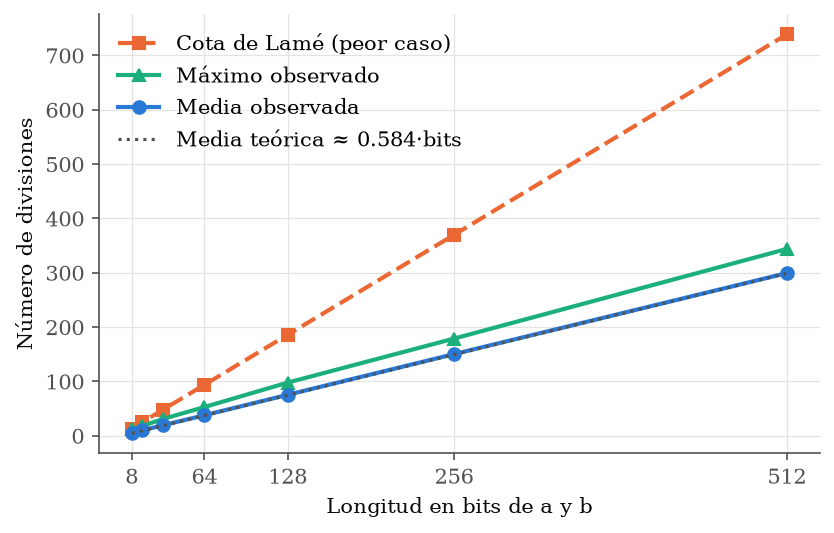

In [27]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv("results/tabla_mcd_ejemplos.csv"))
display(pd.read_csv("results/escenario_A_resumen.csv"))
display(pd.read_csv("results/escenario_A_tiempos.csv"))
display(Image("figures/fig1_euclides_divisiones.png", width=620))

### 7.2 Potencia modular: operaciones frente a bits del exponente

,bits,cuadrados,productos_medios,total_min,total_medio,total_max,directo_log10,t_med_us,t_pocos_unos_us,t_todos_unos_us
0,8,7,4.3,8,11.3,15,2.3,54.0,35.40,78.60
1,16,15,9.0,16,24.0,31,4.7,123.7,74.45,166.95
2,32,31,16.8,32,47.8,63,9.5,251.4,152.95,347.85
3,64,63,32.4,64,95.4,127,19.1,521.6,322.50,713.35
4,128,127,63.2,128,190.2,255,38.4,1036.8,638.65,1432.90
5,256,255,126.3,256,381.3,511,76.9,2146.4,1395.55,3021.30
6,512,511,252.9,512,763.9,1023,154.0,4396.7,2643.30,6011.75
7,1024,1023,510.7,1024,1533.7,2047,308.1,8838.6,5551.80,11925.80


,e,bits,mult_directo,mult_binario,t_directo_us,t_binario_us,aceleracion
0,255,8,254,15,787.6,38.3,20.6
1,4095,12,4094,23,13807.4,59.7,231.3
2,65535,16,65534,31,240519.7,111.6,2155.2


,unos,cuadrados,productos,total,median_us
0,1,1023,1,1024,3314.5
1,64,1023,64,1087,3571.4
2,128,1023,128,1151,3804.5
3,256,1023,256,1279,4238.9
4,384,1023,384,1407,4811.7
5,512,1023,512,1535,5195.0
6,640,1023,640,1663,6149.3
7,768,1023,768,1791,6600.2
8,896,1023,896,1919,6855.0
9,1024,1023,1024,2047,6092.1


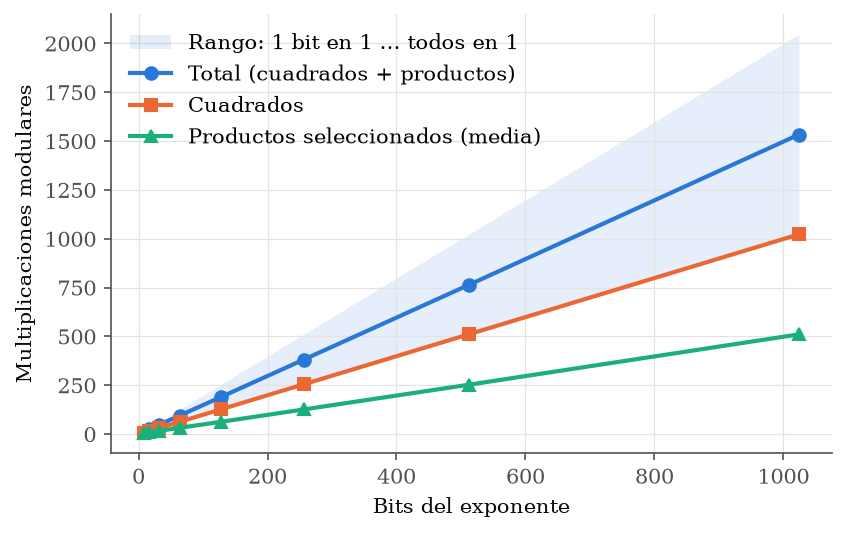

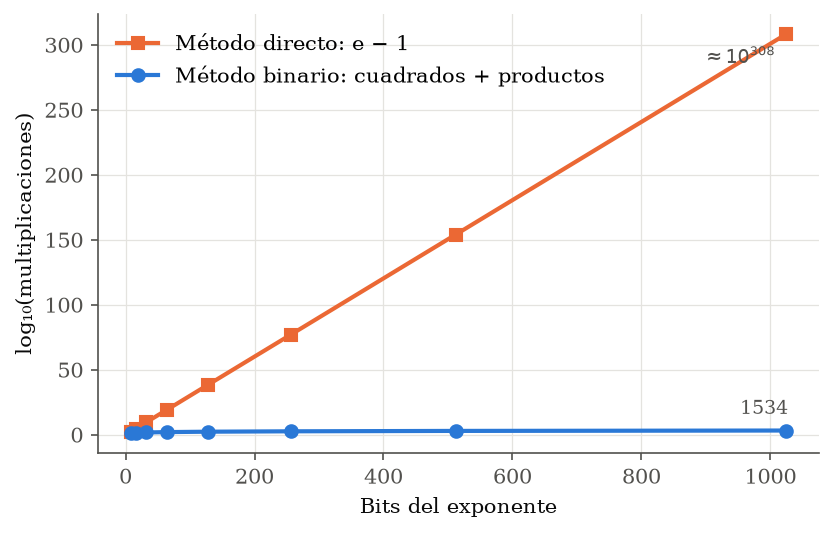

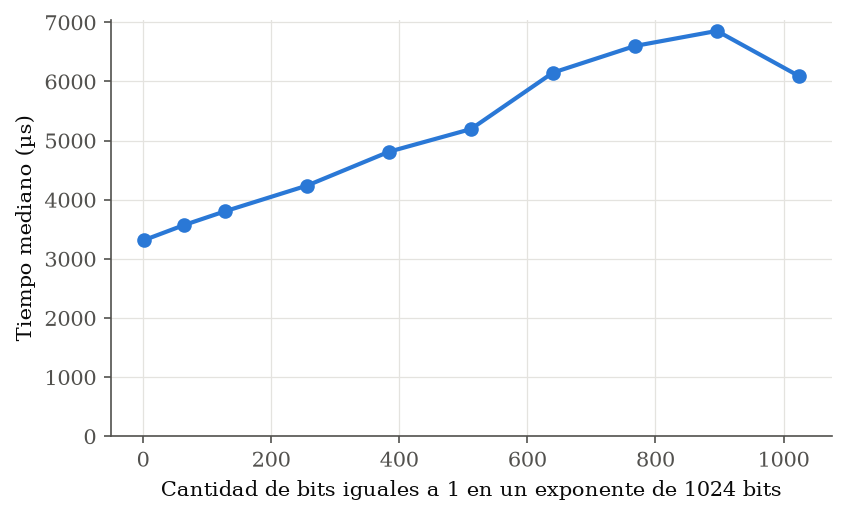

In [28]:
display(pd.read_csv("results/escenario_B_resumen.csv"))
display(pd.read_csv("results/escenario_B_directo_vs_binario.csv"))
display(pd.read_csv("results/escenario_B_unos_1024bits.csv"))
for f in ["fig2_potencia_operaciones.png", "fig3_directo_vs_binario.png", "fig4_unos_tiempo.png"]:
    display(Image("figures/" + f, width=620))

### 7.3 Inversos y congruencias lineales

In [29]:
inv_table, cong_table, crt_trace, stats = resC
display(pd.DataFrame(inv_table))
display(pd.DataFrame(cong_table))
print(stats)

,a,n,mcd,resultado,verificacion
0,7,40,1,23,(7·23) mod 40 = 1
1,-3,11,1,7,(-3·7) mod 11 = 1
2,47,40,1,23,(47·23) mod 40 = 1
3,17,3120,1,2753,(17·2753) mod 3120 = 1
4,6,9,3,Rechazado,ValueError
5,10,25,5,Rechazado,ValueError
6,0,7,7,Rechazado,ValueError
7,14,100,2,Rechazado,ValueError


,congruencia,mcd,esperadas,obtenidas,soluciones
0,14x ≡ 30 (mod 100),2,2,2,"45, 95"
1,6x ≡ 4 (mod 9),3,0,0,—
2,7x ≡ 3 (mod 40),1,1,1,29
3,12x ≡ 18 (mod 30),6,6,6,"4, 9, 14, 19, 24, 29"
4,-4x ≡ 6 (mod 10),2,2,2,"1, 6"
5,35x ≡ 10 (mod 50),5,5,5,"6, 16, 26, 36, 46"


{'inversos': 2000, 'inv_existen': 1209, 'inv_ok': True, 'congruencias': 2000, 'cong_con_sol': 1000, 'cong_ok': True, 'tcr': 1000, 'tcr_ok': True}


## 8. Descarga de evidencias (CSV y PNG)

In [30]:
import glob, zipfile
archivos = glob.glob("results/*.csv") + glob.glob("figures/*.png") + [
    "number_theory.py", "case_generator.py", "test_number_theory.py", "experiments.py"]
with zipfile.ZipFile("lab06_resultados.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in archivos:
        z.write(f)
print(len(archivos), "archivos empaquetados")
try:
    from google.colab import files
    files.download("lab06_resultados.zip")
except ImportError:
    print("Fuera de Colab: el archivo lab06_resultados.zip quedó en el directorio actual.")

20 archivos empaquetados
Fuera de Colab: el archivo lab06_resultados.zip quedó en el directorio actual.
